# Lesson 5 — From pictures to a drill hole

Lesson 4 gave us thousands of pictures of the magnetic rock under Osborne, from two models.
Now the question a company actually pays for: **where should the first hole go — and should we drill at all?**

**Plan**
1. Turn the pictures into a **"chance of hitting magnetic rock"** map (just counting pictures — Lesson 1's region probabilities).
2. Notice the maps are *suspiciously certain*, diagnose why, and **repair the score** (tempering). Check the repair on the held-out lines.
3. Add money: a simple expected-value calculation, including the uncomfortable fact that **magnetite ≠ copper**.
4. **Value of information:** which hole would teach us the most?
5. **Drill, update, repeat:** condition the pictures on a hole's result and redraw the map.

Reuses Lesson 4's saved results (run Lesson 4 first). The repair retrains two flows: ~12 minutes the first time, then cached.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import ensaio
import geomag as gm
import osborne as ob

torch.set_default_dtype(torch.float64)
pd.set_option("display.width", 200)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_DIR = Path("models")
RETRAIN = False

saved = torch.load(MODEL_DIR / "lesson04_pictures.pt")
untempered = {1: saved["theta1"], 2: saved["theta2"]}
NAMES = {1: "Model 1 (one block)", 2: "Model 2 (two blocks)"}

data_path = ensaio.fetch_osborne_magnetic(version=1)
w = ob.load_window(data_path)
w_full = ob.load_window(data_path, every=1)
train = w[w.flight_line.isin(ob.TRAIN_LINES)]; hold = w[w.flight_line.isin(ob.HOLDOUT_LINES)]
T = lambda s: torch.tensor(np.asarray(s, dtype=float))
tr_xyz, tr_y = (T(train.north), T(train.east), T(train.z)), T(train.total_field_anomaly_nt)
ho_xyz, ho_y = (T(hold.north), T(hold.east), T(hold.z)), T(hold.total_field_anomaly_nt)

gn, ge = np.meshgrid(np.arange(-1300, 1501, 25), np.arange(-1900, 501, 25), indexing="ij")
grid_map = griddata((w_full.north, w_full.east), w_full.total_field_anomaly_nt, (gn, ge), method="linear")
pts_n, pts_e = torch.tensor(gn.ravel()), torch.tensor(ge.ravel())

## 1. Chance of hitting magnetic rock

A **vertical hole** drilled at a spot, down to 400 m, hits the magnetic rock in a picture if the spot is inside one of that picture's blocks
(seen from above) and the block's top is shallower than 400 m.
**Chance of a hit = fraction of pictures in which the hole hits.** No formulas — just counting, like Check D in Lesson 1.

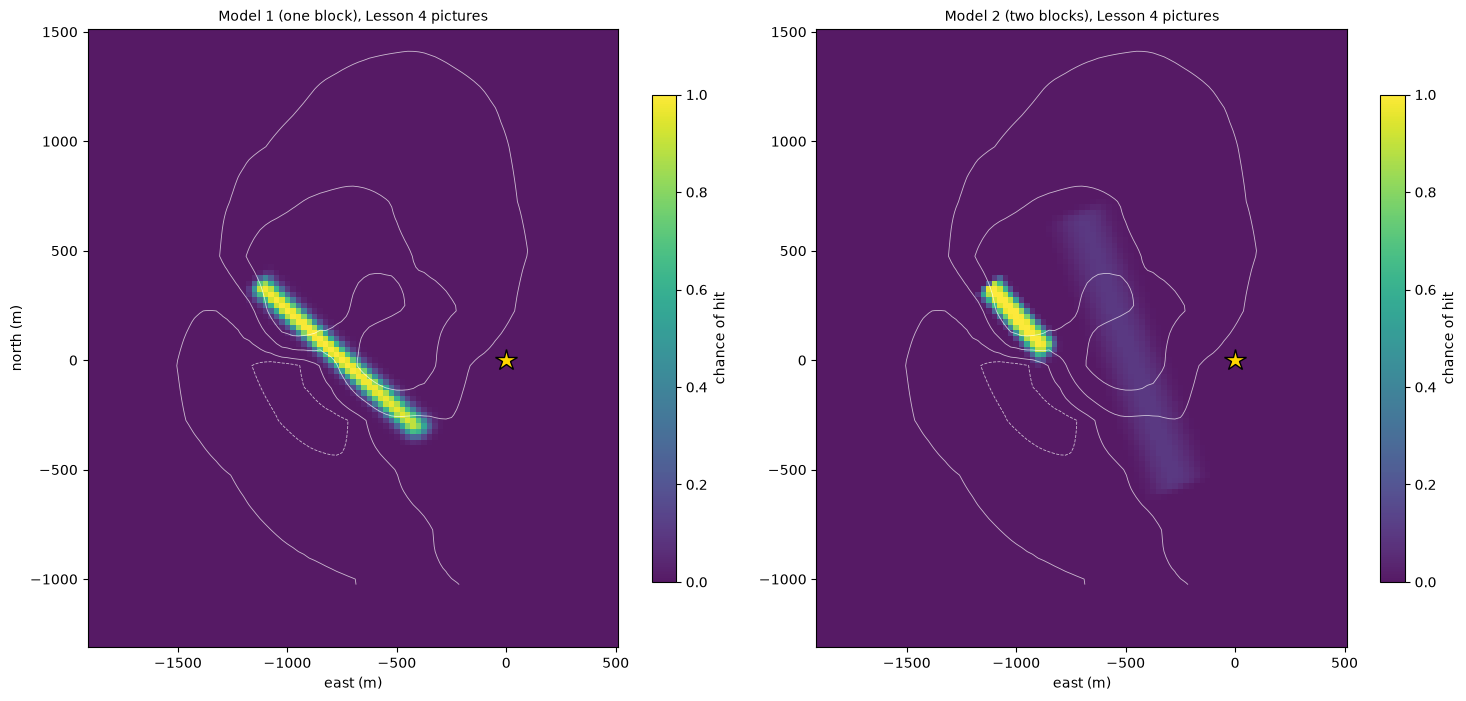

Model 1 (one block): only 2.1% of the map has a chance between 5% and 95%
Model 2 (two blocks): only 4.3% of the map has a chance between 5% and 95%


In [2]:
HOLE_DEPTH = 400.0

def hits(theta, n_blocks, pn, pe, depth=HOLE_DEPTH):
    """(n_pictures, n_points) boolean: does a vertical hole at each point hit a block in each picture?"""
    p = ob.theta_to_phys(theta, n_blocks)
    out = torch.zeros(len(theta), len(pn), dtype=torch.bool)
    for k in range(n_blocks):
        dn = pn[None, :] - p["xc"][:, k:k + 1]; de = pe[None, :] - p["yc"][:, k:k + 1]
        c, s = torch.cos(p["strike"][:, k:k + 1]), torch.sin(p["strike"][:, k:k + 1])
        along, across = dn * c + de * s, -dn * s + de * c
        inside = (along.abs() <= p["length"][:, k:k + 1] / 2) & (across.abs() <= p["width"][:, k:k + 1] / 2)
        out |= inside & (p["top"][:, k:k + 1] <= depth)
    return out

def hit_map(theta, n_blocks):
    return hits(theta, n_blocks, pts_n, pts_e).double().mean(0).reshape(gn.shape).numpy()

def show(ax, field, title, cmap="viridis", vmax=1.0, label="chance of hit"):
    ax.contour(ge, gn, grid_map, levels=[-500, 0, 1000, 2500], colors="w", linewidths=0.6, alpha=0.7)
    im = ax.pcolormesh(ge, gn, field, cmap=cmap, vmin=0, vmax=vmax, shading="auto", alpha=0.9)
    ax.plot(0, 0, "*", color="gold", mec="k", ms=16)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.set_xlabel("east (m)")
    plt.colorbar(im, ax=ax, shrink=0.75, label=label)

maps_raw = {K: hit_map(th, K) for K, th in untempered.items()}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for a, (K, hm) in zip(axes, maps_raw.items()):
    show(a, hm, f"{NAMES[K]}, Lesson 4 pictures")
axes[0].set_ylabel("north (m)"); plt.tight_layout(); plt.show()
for K, hm in maps_raw.items():
    unsure = ((hm > 0.05) & (hm < 0.95)).mean()
    print(f"{NAMES[K]}: only {unsure:.1%} of the map has a chance between 5% and 95%")

(White lines: contours of the measured anomaly. Gold star: the mine's listed position.)

**Suspicious.** Each model is almost perfectly sure — 0% or 100% nearly everywhere — yet the two models disagree with each other,
and Lesson 4 showed Model 2's 90% bands caught only ~2/3 of the held-out readings. Over-certainty, again.

## 2. Diagnose and repair: correlated misfit

The score treats every reading as an **independent** piece of evidence. But most of the misfit is *model error* (blocks aren't the real geology),
and model error at readings 40 m apart is almost the same — so the same evidence gets counted many times over.

**Measure it:** take the best-fit picture, compute the leftovers (reading − prediction) along each training line,
and see how quickly they stop resembling their neighbours (the *autocorrelation*).

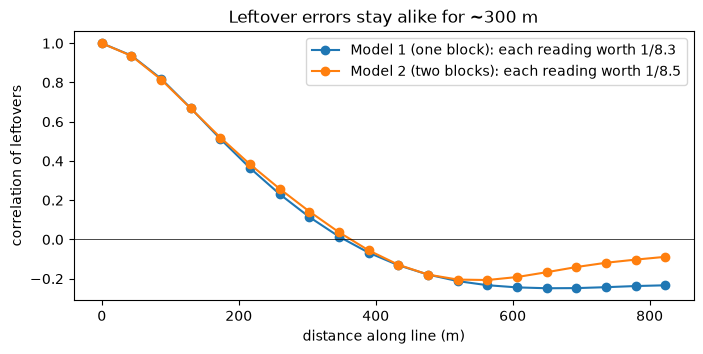

{'Model 1 (one block)': 'temper = 0.120', 'Model 2 (two blocks)': 'temper = 0.117'}


In [3]:
def residual_acf(theta_map, n_blocks, max_lag=20):
    with torch.no_grad():
        r = (tr_y - ob.predict(theta_map[None], n_blocks, *tr_xyz)[0]).numpy()
    acfs = []
    for _, g in train.assign(r=r).groupby("flight_line"):
        x = g.sort_values("east").r.values; x = x - x.mean()
        acfs.append([np.sum(x[: len(x) - k] * x[k:]) / np.sum(x * x) for k in range(max_lag)])
    acf = np.mean(acfs, axis=0)
    first_neg = int(np.argmax(acf < 0)) if (acf < 0).any() else max_lag
    inflation = 1 + 2 * acf[1:first_neg].sum()     # standard 'effective sample size' formula
    return acf, inflation

spacing = np.median(np.diff(train[train.flight_line == ob.TRAIN_LINES[0]].sort_values("east").east))
temper = {}
plt.figure(figsize=(8, 3.5))
for K in (1, 2):
    theta_map = torch.load(MODEL_DIR / f"lesson04_{K}block.pt")["theta_map"]
    acf, infl = residual_acf(theta_map, K)
    temper[K] = 1 / infl
    plt.plot(np.arange(len(acf)) * spacing, acf, "o-", label=f"{NAMES[K]}: each reading worth 1/{infl:.1f}")
plt.axhline(0, color="k", lw=0.5); plt.xlabel("distance along line (m)"); plt.ylabel("correlation of leftovers")
plt.legend(); plt.title("Leftover errors stay alike for ~300 m"); plt.show()
print({NAMES[K]: f"temper = {t:.3f}" for K, t in temper.items()})

Leftovers stay alike for ~8 readings, so the 447 readings are worth only ~1/8 as many independent pieces of evidence.
**Repair:** multiply the log-likelihood by `temper` ≈ 0.12 (a *tempered* or *power* likelihood, a standard fix for misspecified models).
This is still optimistic — misfits on neighbouring *lines* are correlated too — but it's a measured correction, not a fudge.

Retrain both flows with the tempered score (same warm-start recipe as Lesson 4), then re-check on the **held-out lines**.

In [4]:
def tempered_flow(K, n_iter):
    path = MODEL_DIR / f"lesson05_{K}block_tempered.pt"
    post = ob.OsbornePosterior(K, *tr_xyz, tr_y, physics_device=DEV, temper=temper[K])
    theta_map = torch.load(MODEL_DIR / f"lesson04_{K}block.pt")["theta_map"]
    if path.exists() and not RETRAIN:
        s = torch.load(path)
        flow = ob.warm_started_flow(s["theta_map"], s["scale"]); flow.load_state_dict(s["state"]); flow.eval()
        print(f"loaded {path}")
    else:
        print(f"training {NAMES[K]} with temper={temper[K]:.3f}")
        flow, scale, _ = ob.train_flow(post, theta_map, n_iter)
        torch.save({"state": flow.state_dict(), "theta_map": theta_map, "scale": scale}, path)
    with torch.no_grad():
        theta, log_q = flow.sample(4000)
        ess = gm.importance_ess(post.log_prob(theta), log_q)
    return theta, ess

tempered, ess_t = {}, {}
for K, n_iter in [(1, 2000), (2, 3000)]:
    tempered[K], ess_t[K] = tempered_flow(K, n_iter)

loaded models\lesson05_1block_tempered.pt


loaded models\lesson05_2block_tempered.pt


In [5]:
def held_out_scores(theta, n_blocks, n=1000):
    with torch.no_grad():
        pred = ob.predict(theta[:n], n_blocks, *ho_xyz)
        sigma = ob.theta_to_phys(theta[:n], n_blocks)["sigma"][:, None]
    sim = pred + sigma * torch.randn(pred.shape, generator=torch.Generator().manual_seed(0))
    lo, hi = torch.quantile(sim, 0.05, dim=0), torch.quantile(sim, 0.95, dim=0)
    cover = ((ho_y >= lo) & (ho_y <= hi)).double().mean().item()
    log_lik = (-0.5 * ((ho_y - pred) / sigma) ** 2 - torch.log(sigma) - 0.5 * np.log(2 * np.pi)).sum(1)
    log_score = (torch.logsumexp(log_lik, 0) - np.log(n)).item()
    return cover, log_score

rows = []
for K in (1, 2):
    for label, th in [("Lesson 4 (untempered)", untempered[K]), ("tempered", tempered[K])]:
        cover, score = held_out_scores(th, K)
        hm = hit_map(th, K)
        rows.append(dict(model=NAMES[K], version=label, **{"held-out readings inside 90% band": cover,
                    "held-out log score": score, "map area with 5–95% chance": ((hm > 0.05) & (hm < 0.95)).mean()}))
comparison = pd.DataFrame(rows).set_index(["model", "version"])
print({NAMES[K]: f"tempered flow importance ESS {e:.0%}" for K, e in ess_t.items()})
comparison.round(3)

{'Model 1 (one block)': 'tempered flow importance ESS 40%', 'Model 2 (two blocks)': 'tempered flow importance ESS 11%'}


held-out readings inside 90% band  held-out log score  map area with 5–95% chance
model                version                                                                                                 
Model 1 (one block)  Lesson 4 (untempered)                              0.924           -1225.713                       0.021
                     tempered                                           0.930           -1212.339                       0.071
Model 2 (two blocks) Lesson 4 (untempered)                              0.673           -1980.875                       0.043
                     tempered                                           0.795           -1488.158                       0.130

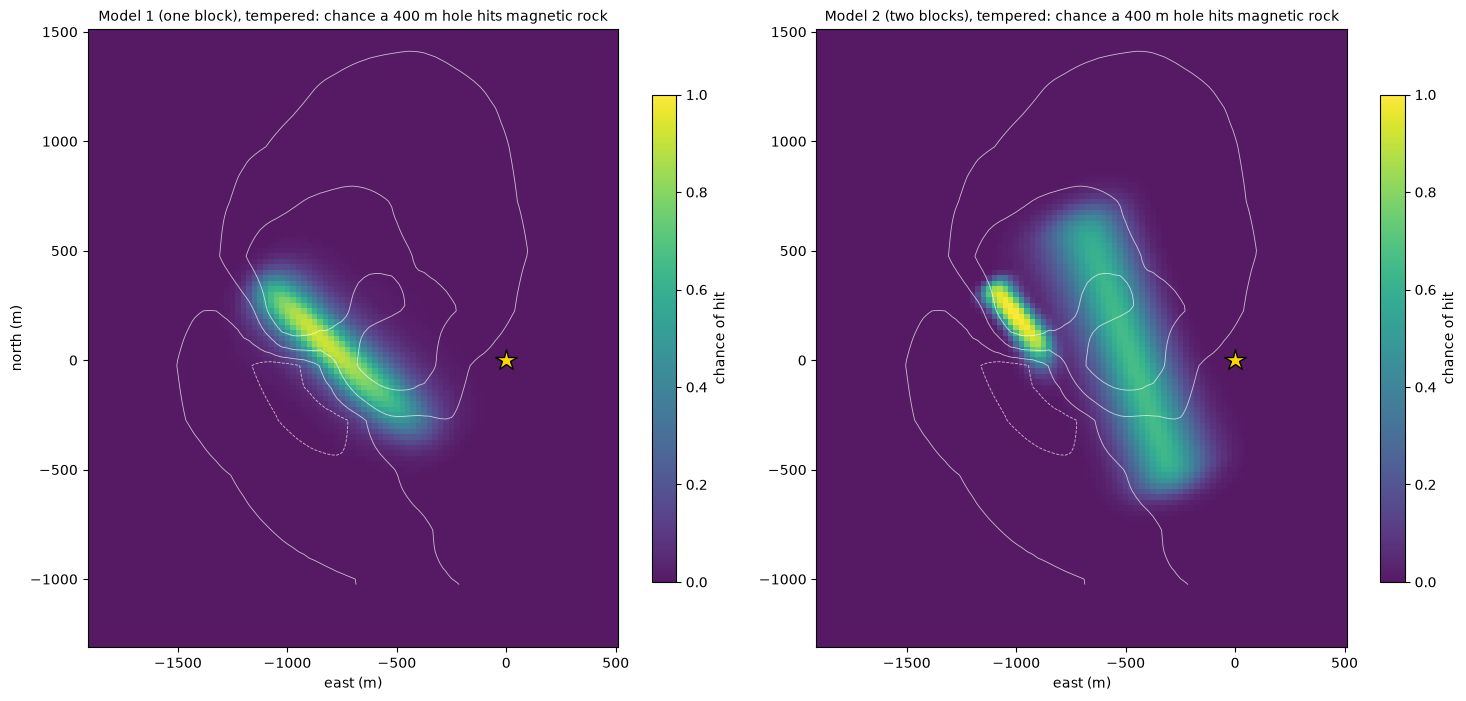

In [6]:
maps = {K: hit_map(th, K) for K, th in tempered.items()}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for a, (K, hm) in zip(axes, maps.items()):
    show(a, hm, f"{NAMES[K]}, tempered: chance a 400 m hole hits magnetic rock")
axes[0].set_ylabel("north (m)"); plt.tight_layout(); plt.show()

Compare the table rows: tempering widens each model's uncertainty, and the held-out lines tell us whether that made the model **more honest**
(90% bands catching closer to 90% of unseen readings, and a better held-out log score).

**In our run:** Model 2's held-out coverage rose from ~67% to ~80% and its held-out log score improved by several hundred units;
Model 1 was already honest-ish (~92%) and improved slightly. Both maps now have real "maybe" zones instead of hard 0/100% edges.
Two cautions: Model 2 is still somewhat overconfident (80% < 90%) because we only corrected for correlation *along* lines;
and the tempered Model 1 flow has a low importance ESS, so its map is a rougher approximation (train longer, or reweight by `p/q`, on a real job).

### Combining the two models
Weight each model by how well it predicted the held-out lines (its held-out log score). Then the combined map is the weighted average.

In [7]:
scores = {K: comparison.loc[(NAMES[K], "tempered"), "held-out log score"] for K in (1, 2)}
d = scores[1] - scores[2]
weight = {1: 1 / (1 + np.exp(-d)), 2: 1 / (1 + np.exp(d))}
combined = weight[1] * maps[1] + weight[2] * maps[2]
print({NAMES[K]: f"weight {weight[K]:.4f}" for K in (1, 2)})

{'Model 1 (one block)': 'weight 1.0000', 'Model 2 (two blocks)': 'weight 0.0000'}


Held-out log scores reward honesty about error, which is what you want for decisions — but they can't tell you the geology,
and with only three held-out lines they can be lopsided. A geologist would add: "two-plus bodies; don't trust either model's exact outlines".
So below we look at the combined map **and** at where the two models disagree.

## 3. Add money (illustrative numbers)

- A 400 m hole costs about **$0.3 M** (assumed, illustrative).
- If a hole hits magnetic ironstone **and** that ironstone carries ore, the discovery is worth, say, **$50 M** at this stage.
- The catch: hitting magnetite isn't hitting copper. Osborne's own history — 97 holes into the anomaly before the discovery hole —
  says the chance a given ironstone hit is economic is low. Call it **q** and try a few values.

Expected value of a hole = P(hit) × q × $50 M − $0.3 M.

In [8]:
COST, PRIZE = 0.3, 50.0
i_best = np.unravel_index(np.argmax(combined), combined.shape)
p_best = combined[i_best]
print(f"best hole on the combined map: north {gn[i_best]:.0f}, east {ge[i_best]:.0f}, P(hit) = {p_best:.0%}")
for q in [0.005, 0.02, 0.1]:
    print(f"  q = {q:5.1%}:  expected value {p_best * q * PRIZE - COST:+.2f} $M")
print(f"break-even q: {COST / (p_best * PRIZE):.1%}")

best hole on the combined map: north 100, east -850, P(hit) = 92%
  q =  0.5%:  expected value -0.07 $M
  q =  2.0%:  expected value +0.62 $M
  q = 10.0%:  expected value +4.30 $M
break-even q: 0.7%


**Where** to drill comes from the map. **Whether** to drill hinges on q — the part magnetics can't see.
That's why real programs add gravity, electrical surveys and geology before spending money.

## 4. Value of information: which hole teaches us most?

If the first hole is to *learn*, drill where the outcome is most uncertain — about half the pictures say "hit", half say "miss".
The **outcome entropy** `H = −p·log₂p − (1−p)·log₂(1−p)` (bits) is largest at p = 50%.
A different kind of informative hole: where the **two models disagree most** — its result tells us which model to trust.

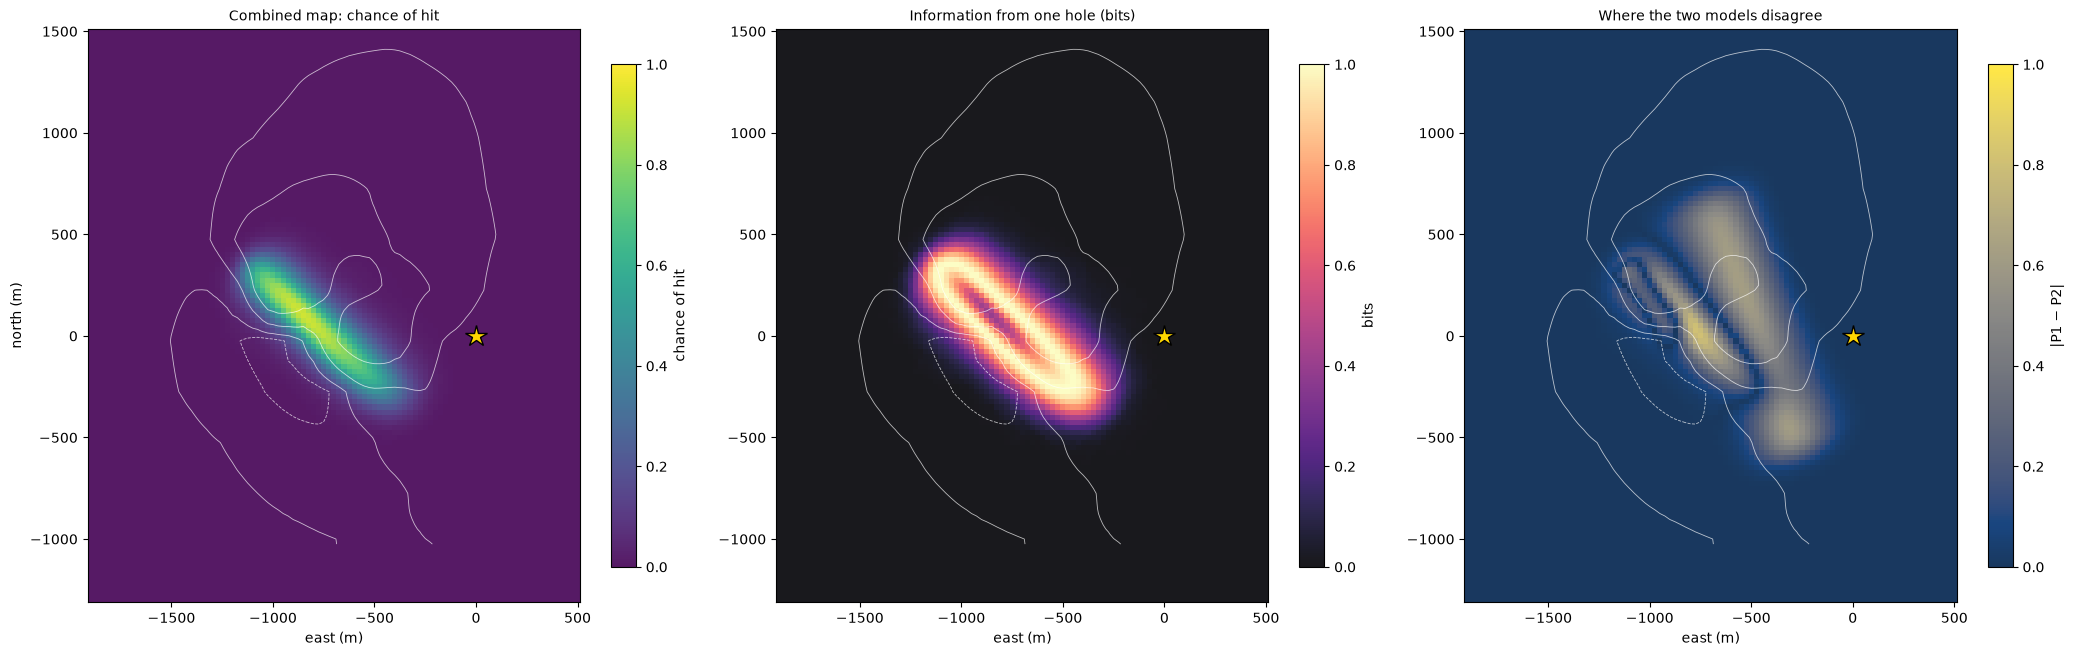

most-likely-to-hit   hole: north   100, east   -850   P(hit): Model 1  92%, Model 2  45%, combined  92%
most informative     hole: north  -250, east   -550   P(hit): Model 1  50%, Model 2  27%, combined  50%
model-deciding       hole: north    25, east   -775   P(hit): Model 1  90%, Model 2   9%, combined  90%


In [9]:
def entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

disagree = np.abs(maps[1] - maps[2])
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
show(axes[0], combined, "Combined map: chance of hit")
show(axes[1], entropy(combined), "Information from one hole (bits)", cmap="magma", label="bits")
show(axes[2], disagree, "Where the two models disagree", cmap="cividis", label="|P1 − P2|")
axes[0].set_ylabel("north (m)"); plt.tight_layout(); plt.show()

i_info = np.unravel_index(np.argmax(entropy(combined)), combined.shape)
i_dis = np.unravel_index(np.argmax(disagree), disagree.shape)
for label, i in [("most-likely-to-hit", i_best), ("most informative", i_info), ("model-deciding", i_dis)]:
    print(f"{label:20s} hole: north {gn[i]:5.0f}, east {ge[i]:6.0f}   P(hit): Model 1 {maps[1][i]:4.0%}, Model 2 {maps[2][i]:4.0%}, combined {combined[i]:4.0%}")

## 5. Drill, update, repeat

Suppose we drill the **most informative** hole. Its result is a new fact; every picture either agrees with it or doesn't.
The quickest update: **keep only the pictures that agree** (*rejection*) and redraw the map — no retraining.
(When too few pictures survive, add the drill result to the score and retrain the flow — the loop from the conversation.)

We don't know the real result, so we show both branches, for the model with more weight.

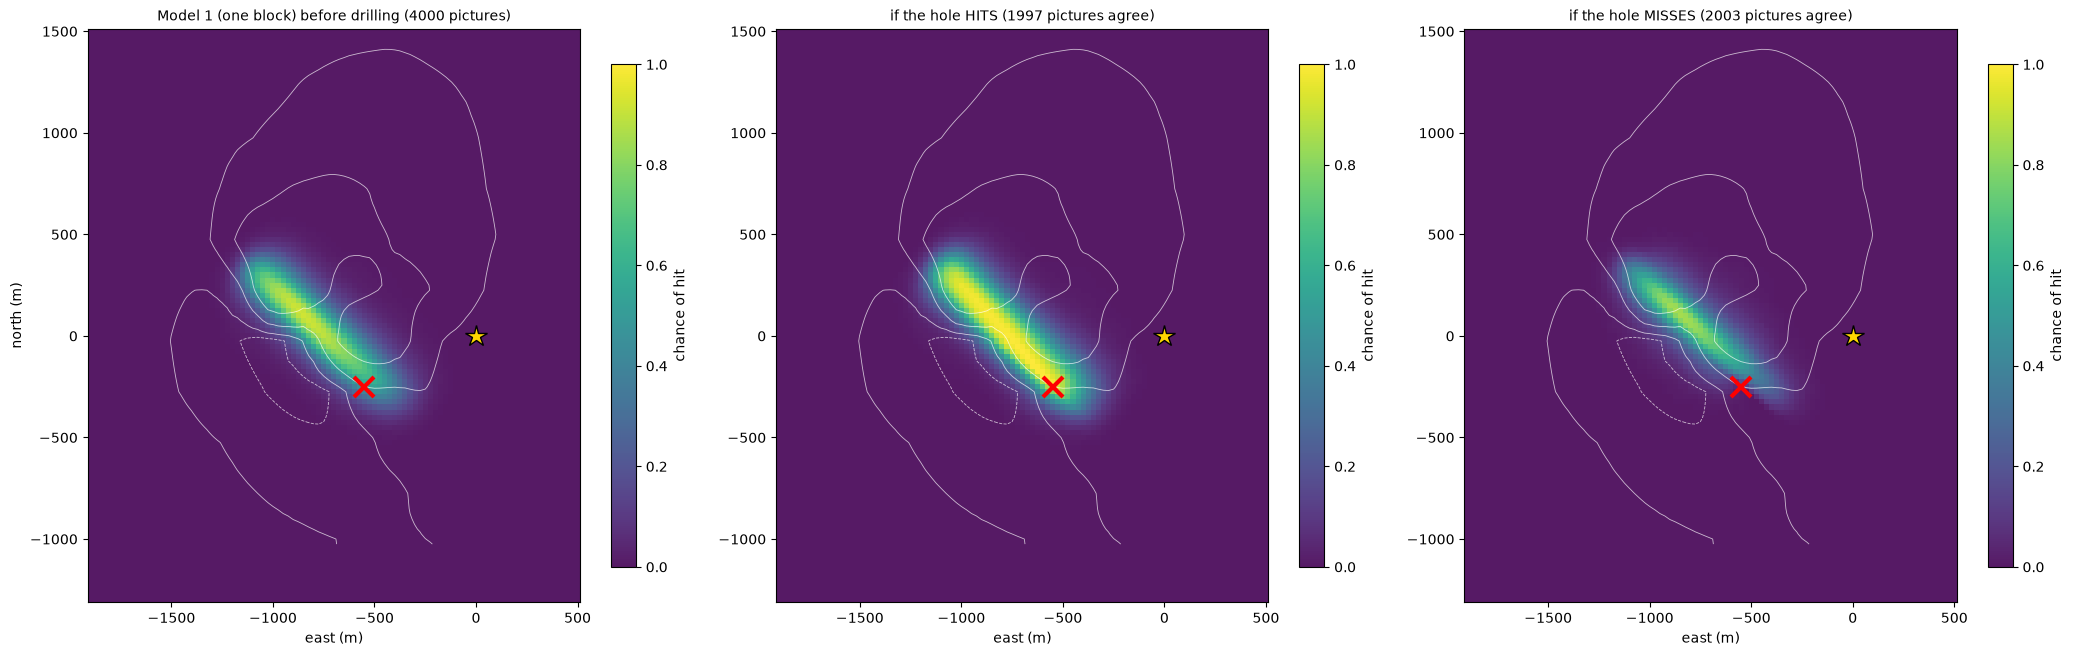

In [10]:
K_main = 1 if weight[1] >= weight[2] else 2
th_main = tempered[K_main]
HOLE = (float(gn[i_info]), float(ge[i_info]))
hole_hit = hits(th_main, K_main, torch.tensor([HOLE[0]]), torch.tensor([HOLE[1]]))[:, 0]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
show(axes[0], maps[K_main], f"{NAMES[K_main]} before drilling ({len(th_main)} pictures)")
branches = {}
for a, (label, keep) in zip(axes[1:], [("if the hole HITS", hole_hit), ("if the hole MISSES", ~hole_hit)]):
    n_keep = int(keep.sum())
    branches[label] = n_keep
    if n_keep == 0:
        a.set_title(f"{label}: no pictures agree — the model must be retrained"); continue
    show(a, hit_map(th_main[keep], K_main), f"{label} ({n_keep} pictures agree)")
for a in axes:
    a.plot(HOLE[1], HOLE[0], "rx", ms=14, mew=3)
axes[0].set_ylabel("north (m)"); plt.tight_layout(); plt.show()

The red ✗ is the hole. Either result sharpens the map. If a result is one the model thought unlikely, only a few pictures survive —
a loud hint that the model itself needs rethinking, not just its numbers.

## Report card
Software/method sanity checks. The scientific findings are in the tables above.

In [11]:
results = {
    "hit maps are probabilities": all(0 <= m.min() and m.max() <= 1 for m in list(maps.values()) + [combined]),
    "tempered flows produced usable samples (ESS > 2%)": all(e > 0.02 for e in ess_t.values()),
    "model weights add to 1": abs(weight[1] + weight[2] - 1) < 1e-12,
    "hit and miss branches account for every picture": sum(branches.values()) == len(th_main),
    "after a hit, every surviving picture hits at the hole": bool(hits(th_main[hole_hit], K_main, torch.tensor([HOLE[0]]), torch.tensor([HOLE[1]])).all()) if hole_hit.any() else True,
    "outcome entropy never exceeds 1 bit": entropy(combined).max() <= 1 + 1e-9,
}
for k, v in results.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(results.values()), "some checks failed"

PASS  hit maps are probabilities
PASS  tempered flows produced usable samples (ESS > 2%)
PASS  model weights add to 1
PASS  hit and miss branches account for every picture
PASS  after a hit, every surviving picture hits at the hole
PASS  outcome entropy never exceeds 1 bit


## Take-aways — the whole game
1. **Pictures, not a picture.** A flow turns readings into thousands of possible undergrounds; decisions come from *counting* them.
2. **Be suspicious of certainty.** Correlated model error made both models absurdly sure of themselves. Measuring the correlation and tempering is one honest repair; the held-out lines judge whether it worked.
3. **Where vs. whether.** The map says where; whether depends on what magnetics can't see (does the magnetite carry copper?).
4. **Model uncertainty matters.** Two reasonable models give different maps. Held-out data helps weigh them, but rewards honesty, not geology.
5. **Drill to learn, then loop.** The most valuable first hole can be the one that settles the biggest question. Each hole updates the pictures.

Real exploration feeds more data types (gravity, electrical, geochemistry, geology maps) into the same score — and a conditional flow can take them all as its "recipe card".